# Q1. MLPs and memorization (25 marks)

**Dataset and split:** CIFAR-10, with 45,000 training images and 5,000 validation images. The split is stratified using seed **26001**, obtained from roll number **M26MAC001**. The official test set is used only for the final model evaluation.

**Roll Number:** M26MAC001  
**Split seed:** 26001

In [2]:
from pathlib import Path
import os, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

ROLL_NUMBER = "M26MAC001"
SEED = int(''.join(ch for ch in ROLL_NUMBER if ch.isdigit()))
assert SEED == 26001
DATA_DIR = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Roll:', ROLL_NUMBER, '| seed:', SEED, '| device:', DEVICE)
print('PyTorch:', torch.__version__)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

Roll: M26MAC001 | seed: 26001 | device: cpu
PyTorch: 2.15.0+cpu


##  Download CIFAR-10 and create the fixed split

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_data = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=transform)
labels = np.asarray(train_data.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(train_data)), train_size=45000, test_size=5000,
    random_state=SEED, stratify=labels,
)
assert len(train_idx) == 45000 and len(val_idx) == 5000
assert not np.intersect1d(train_idx, val_idx).size
np.savez(RESULTS / 'split_seed_26001.npz', train_indices=train_idx, val_indices=val_idx,
         seed=SEED, roll_number=ROLL_NUMBER)
print('Training:', len(train_idx), '| validation:', len(val_idx))
print(pd.DataFrame({'class': train_data.classes,
                    'training': np.bincount(labels[train_idx], minlength=10),
                    'validation': np.bincount(labels[val_idx], minlength=10)}).to_string(index=False))

Training: 45000 | validation: 5000
     class  training  validation
  airplane      4500         500
automobile      4500         500
      bird      4500         500
       cat      4500         500
      deer      4500         500
       dog      4500         500
      frog      4500         500
     horse      4500         500
      ship      4500         500
     truck      4500         500


## Q1(a). Why can an MLP perform poorly on CIFAR-10?

We compare a shallow MLP with one hidden layer of 512 units against a deeper MLP with two hidden layers of 450 units each. The question is whether extra nonlinear depth helps the network learn a better representation, while keeping the parameter budgets close.

For a fair comparison, both models use the same split, input pixels, optimizer (AdamW), learning rate (0.001), batch size (128), weight decay (0.0001), and 25-epoch budget. They have 1,578,506 and 1,590,310 trainable parameters respectively: a difference of about 0.75%. Each checkpoint is chosen by the lowest validation loss. The models differ in depth and computation, so this experiment does not isolate every possible cause of the difference.

In [3]:
BATCH_SIZE = 128
EPOCHS = 25
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

class MLP(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()
        sizes = [3 * 32 * 32, *hidden_sizes, 10]
        layers = [nn.Flatten()]
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                layers.append(nn.ReLU())
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_loader(dataset, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
                      generator=generator)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    criterion = nn.CrossEntropyLoss(reduction='sum')
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += criterion(logits, y).item()
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return loss_sum / total, correct / total

def train_epoch(model, loader, optimizer):
    model.train()
    loss_sum = 0.0
    correct = 0
    total = 0
    criterion = nn.CrossEntropyLoss()
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return loss_sum / total, correct / total

models = {'shallow': [512], 'deep': [450, 450]}
counts = {name: parameter_count(MLP(hidden)) for name, hidden in models.items()}
for name, count in counts.items():
    print(f'{name}: {models[name]} hidden units, {count:,} trainable parameters')
print(f"Relative difference: {abs(counts['deep'] - counts['shallow']) / counts['shallow'] * 100:.2f}%")

shallow: [512] hidden units, 1,578,506 trainable parameters
deep: [450, 450] hidden units, 1,590,310 trainable parameters
Relative difference: 0.75%


In [6]:
def fit_comparison(name, hidden):
    seed_everything(SEED)
    model = MLP(hidden).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    train_loader = make_loader(Subset(train_data, train_idx), shuffle=True)
    val_loader = make_loader(Subset(train_data, val_idx))
    history = []
    best_val_loss = float('inf')
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)
        row = {'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
               'val_loss': val_loss, 'val_acc': val_acc}
        history.append(row)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({'model_state': model.state_dict(), 'hidden': hidden, 'epoch': epoch,
                        'val_loss': val_loss, 'roll': ROLL_NUMBER, 'seed': SEED},
                       RESULTS / f'{name}_best.pt')
        print(f"{name:7s} {epoch:2d}/{EPOCHS} | train acc {train_acc:.3f} | val acc {val_acc:.3f} | val loss {val_loss:.3f}")
    print(f'{name} elapsed: {(time.time() - start) / 60:.1f} minutes')
    df = pd.DataFrame(history)
    df.to_csv(RESULTS / f'{name}_history.csv', index=False)
    return df

histories = {name: fit_comparison(name, hidden) for name, hidden in models.items()}

shallow  1/25 | train acc 0.416 | val acc 0.459 | val loss 1.551
shallow  2/25 | train acc 0.485 | val acc 0.470 | val loss 1.527
shallow  3/25 | train acc 0.520 | val acc 0.484 | val loss 1.502
shallow  4/25 | train acc 0.539 | val acc 0.504 | val loss 1.484
shallow  5/25 | train acc 0.566 | val acc 0.497 | val loss 1.518
shallow  6/25 | train acc 0.590 | val acc 0.520 | val loss 1.513
shallow  7/25 | train acc 0.609 | val acc 0.512 | val loss 1.530
shallow  8/25 | train acc 0.626 | val acc 0.503 | val loss 1.533
shallow  9/25 | train acc 0.646 | val acc 0.489 | val loss 1.742
shallow 10/25 | train acc 0.660 | val acc 0.508 | val loss 1.601
shallow 11/25 | train acc 0.680 | val acc 0.522 | val loss 1.635
shallow 12/25 | train acc 0.691 | val acc 0.522 | val loss 1.651
shallow 13/25 | train acc 0.709 | val acc 0.495 | val loss 1.801
shallow 14/25 | train acc 0.727 | val acc 0.504 | val loss 1.850
shallow 15/25 | train acc 0.742 | val acc 0.517 | val loss 1.811
shallow 16/25 | train acc

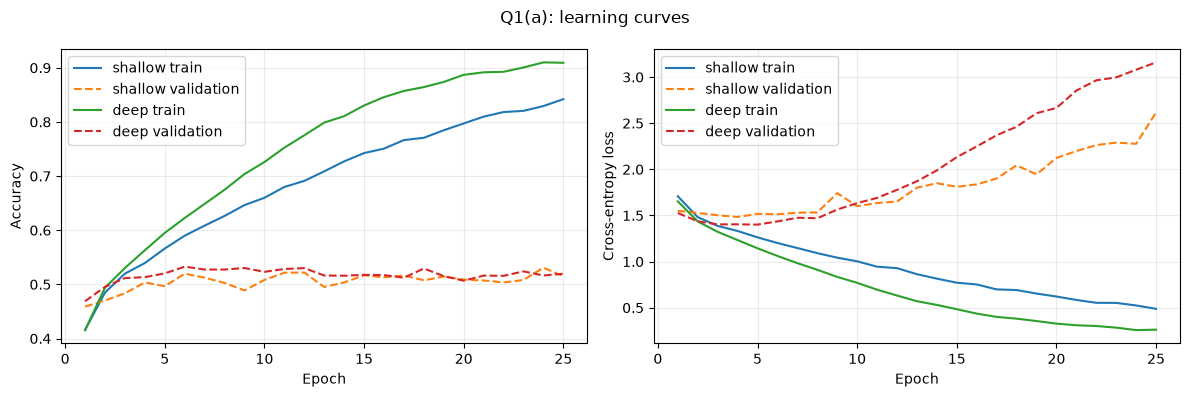

shallow: selected epoch 4, validation accuracy 0.5036, validation loss 1.4835
deep: selected epoch 5, validation accuracy 0.5202, validation loss 1.4007


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, df in histories.items():
    axes[0].plot(df.epoch, df.train_acc, label=f'{name} train')
    axes[0].plot(df.epoch, df.val_acc, '--', label=f'{name} validation')
    axes[1].plot(df.epoch, df.train_loss, label=f'{name} train')
    axes[1].plot(df.epoch, df.val_loss, '--', label=f'{name} validation')
for ax, ylabel in zip(axes, ['Accuracy', 'Cross-entropy loss']):
    ax.set(xlabel='Epoch', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle('Q1(a): learning curves')
fig.tight_layout()
fig.savefig(RESULTS / 'q1a_learning_curves.png', dpi=180, bbox_inches='tight')
plt.show()
for name, df in histories.items():
    best = df.loc[df.val_loss.idxmin()]
    print(f"{name}: selected epoch {int(best.epoch)}, validation accuracy {best.val_acc:.4f}, validation loss {best.val_loss:.4f}")

### Q1(a). Learning curves

At epoch 25, online training accuracy reached 84.21% for the shallow MLP and 90.93% for the deep MLP, while validation accuracy was 51.50% and 51.96%, respectively. Both curves show a substantial train–validation gap, consistent with overfitting. Training accuracy is measured while weights change during an epoch, whereas validation accuracy is measured at the end of the epoch, so the two measurements are not perfectly identical in timing.

## Q1(b). Learning useful structure and memorizing incorrect labels

We train a larger MLP with two 2,048-unit hidden layers on a stratified subset of 5,000 training images. Half of the labels are deliberately replaced with a different class. We track validation accuracy, accuracy on clean-label training examples, and accuracy against both the true and wrong labels of corrupted examples throughout training. Wrong-label accuracy tells us whether the model is fitting the deliberately incorrect labels; the clean validation set measures whether it learned transferable structure.

In [ ]:
MEM_SIZE = 5000
MEM_EPOCHS = 100
MEM_HIDDEN = [2048, 2048]
MEM_LR = 0.001
MEM_WEIGHT_DECAY = 0.0

mem_idx, _ = train_test_split(train_idx, train_size=MEM_SIZE, random_state=SEED,
                              stratify=labels[train_idx])
rng = np.random.default_rng(SEED)
corrupted_mask = np.zeros(MEM_SIZE, dtype=bool)
corrupted_mask[rng.choice(MEM_SIZE, MEM_SIZE // 2, replace=False)] = True
true_labels = labels[mem_idx].copy()
assigned_labels = true_labels.copy()

assigned_labels[corrupted_mask] = (true_labels[corrupted_mask] +
                                  rng.integers(1, 10, size=corrupted_mask.sum())) % 10
assert np.all(assigned_labels[corrupted_mask] != true_labels[corrupted_mask])
np.savez(RESULTS / 'memorization_setup.npz', indices=mem_idx, true_labels=true_labels,
         assigned_labels=assigned_labels, corrupted_mask=corrupted_mask, seed=SEED)

class AssignedLabelDataset(Dataset):
    def __init__(self, base, indices, assigned):
        self.base, self.indices, self.assigned = base, indices, assigned
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        image, _ = self.base[int(self.indices[i])]
        return image, int(self.assigned[i])

mem_train = AssignedLabelDataset(train_data, mem_idx, assigned_labels)
clean_part = AssignedLabelDataset(train_data, mem_idx[~corrupted_mask], true_labels[~corrupted_mask])
corrupt_true = AssignedLabelDataset(train_data, mem_idx[corrupted_mask], true_labels[corrupted_mask])
corrupt_wrong = AssignedLabelDataset(train_data, mem_idx[corrupted_mask], assigned_labels[corrupted_mask])
mem_loaders = {
    'clean_train_acc': make_loader(clean_part),
    'corrupted_true_acc': make_loader(corrupt_true),
    'corrupted_wrong_acc': make_loader(corrupt_wrong),
    'val_acc': make_loader(Subset(train_data, val_idx)),
}
print('Memorization model parameters:', f'{parameter_count(MLP(MEM_HIDDEN)):,}')
print('Examples:', MEM_SIZE, '| clean labels:', (~corrupted_mask).sum(), '| changed labels:', corrupted_mask.sum())

Memorization model parameters: 10,510,346
Examples: 5000 | clean labels: 2500 | changed labels: 2500


In [9]:
seed_everything(SEED)
mem_model = MLP(MEM_HIDDEN).to(DEVICE)
mem_optimizer = torch.optim.AdamW(mem_model.parameters(), lr=MEM_LR, weight_decay=MEM_WEIGHT_DECAY)
mem_train_loader = make_loader(mem_train, shuffle=True)
mem_history = []
start = time.time()
for epoch in range(1, MEM_EPOCHS + 1):
    loss, online_acc = train_epoch(mem_model, mem_train_loader, mem_optimizer)
    row = {'epoch': epoch, 'train_loss': loss, 'online_train_acc': online_acc}
    for name, loader in mem_loaders.items():
        _, row[name] = evaluate(mem_model, loader)
    mem_history.append(row)
    if epoch == 1 or epoch % 5 == 0 or epoch == MEM_EPOCHS:
        print(f"{epoch:3d}/{MEM_EPOCHS} | val {row['val_acc']:.3f} | corrupted: true {row['corrupted_true_acc']:.3f}, wrong {row['corrupted_wrong_acc']:.3f}")
mem_df = pd.DataFrame(mem_history)
mem_df.to_csv(RESULTS / 'memorization_history.csv', index=False)
torch.save({'model_state': mem_model.state_dict(), 'hidden': MEM_HIDDEN,
            'epoch': MEM_EPOCHS, 'seed': SEED}, RESULTS / 'memorization_final.pt')
print(f'Elapsed: {(time.time() - start) / 60:.1f} minutes')

  1/100 | val 0.283 | corrupted: true 0.279, wrong 0.100
  5/100 | val 0.295 | corrupted: true 0.261, wrong 0.190
 10/100 | val 0.283 | corrupted: true 0.162, wrong 0.453
 15/100 | val 0.242 | corrupted: true 0.078, wrong 0.681
 20/100 | val 0.249 | corrupted: true 0.063, wrong 0.782
 25/100 | val 0.241 | corrupted: true 0.042, wrong 0.830
 30/100 | val 0.226 | corrupted: true 0.015, wrong 0.922
 35/100 | val 0.240 | corrupted: true 0.038, wrong 0.842
 40/100 | val 0.243 | corrupted: true 0.012, wrong 0.954
 45/100 | val 0.237 | corrupted: true 0.025, wrong 0.893
 50/100 | val 0.231 | corrupted: true 0.016, wrong 0.950
 55/100 | val 0.228 | corrupted: true 0.026, wrong 0.855
 60/100 | val 0.247 | corrupted: true 0.016, wrong 0.940
 65/100 | val 0.248 | corrupted: true 0.022, wrong 0.918
 70/100 | val 0.228 | corrupted: true 0.012, wrong 0.910
 75/100 | val 0.239 | corrupted: true 0.002, wrong 0.994
 80/100 | val 0.245 | corrupted: true 0.001, wrong 0.996
 85/100 | val 0.215 | corrupted

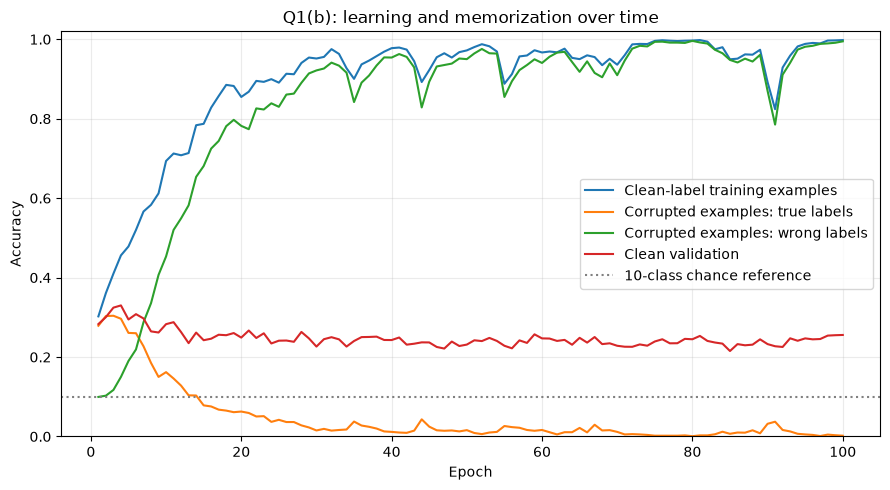

Selected trajectory points:


,epoch,train_loss,online_train_acc,clean_train_acc,corrupted_true_acc,corrupted_wrong_acc,val_acc
0,1,2.3916,0.1506,0.3024,0.2788,0.0996,0.2830
25,26,0.5143,0.8350,0.9132,0.0364,0.8608,0.2416
50,51,0.1176,0.9616,0.9804,0.0088,0.9644,0.2422
99,100,0.0156,0.9948,0.9980,0.0020,0.9948,0.2556


First epoch with >=90% accuracy on wrong labels: 29
Peak validation accuracy: 0.33 at epoch 4


In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for col, label in [('clean_train_acc', 'Clean-label training examples'),
                   ('corrupted_true_acc', 'Corrupted examples: true labels'),
                   ('corrupted_wrong_acc', 'Corrupted examples: wrong labels'),
                   ('val_acc', 'Clean validation')]:
    ax.plot(mem_df.epoch, mem_df[col], label=label)
ax.axhline(0.1, color='gray', linestyle=':', label='10-class chance reference')
ax.set(xlabel='Epoch', ylabel='Accuracy', title='Q1(b): learning and memorization over time', ylim=(0, 1.02))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'q1b_memorization.png', dpi=180, bbox_inches='tight')
plt.show()
print('Selected trajectory points:')
display(mem_df.iloc[sorted(set([0, len(mem_df)//4, len(mem_df)//2, len(mem_df)-1]))].round(4))
first_90 = mem_df.loc[mem_df.corrupted_wrong_acc >= 0.90, 'epoch']
print('First epoch with >=90% accuracy on wrong labels:', int(first_90.iloc[0]) if len(first_90) else 'not reached')
print('Peak validation accuracy:', round(mem_df.val_acc.max(), 4), 'at epoch', int(mem_df.loc[mem_df.val_acc.idxmax(), 'epoch']))

### Q1(b). Result and interpretation

Validation accuracy peaked at **33.00% in epoch 4**, when accuracy on the deliberately wrong labels was only **15.00%**. Wrong-label accuracy first exceeded 90% at epoch 29 (91.40%), by which time validation accuracy was 24.70%. At epoch 100, wrong-label accuracy was 99.48% and validation accuracy was 25.56%.

This trajectory supports the conclusion that the MLP learned some transferable structure early, then increasingly fitted the incorrect labels. The measurements do not identify one exact instant when memorization began.

## Q1(a). Final test results

The comparison models and their checkpoints were selected using validation data. The next cell reports their official test results.

In [11]:
test_data = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=transform)
test_loader = make_loader(test_data)
rows = []
for name, hidden in models.items():
    checkpoint = torch.load(RESULTS / f'{name}_best.pt', map_location=DEVICE, weights_only=False)
    model = MLP(hidden).to(DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({'model': name, 'hidden_sizes': str(hidden), 'parameters': counts[name],
                 'selected_epoch': checkpoint['epoch'], 'selected_val_loss': checkpoint['val_loss'],
                 'test_loss': test_loss, 'test_accuracy': test_acc})
summary = pd.DataFrame(rows)
summary.to_csv(RESULTS / 'q1a_final_test_results.csv', index=False)
display(summary.round(4))

,model,hidden_sizes,parameters,selected_epoch,selected_val_loss,test_loss,test_accuracy
0,shallow,[512],1578506,4,1.4835,1.4646,0.5045
1,deep,"[450, 450]",1590310,5,1.4007,1.3947,0.5193


### Q1(a). Answer

The shallow model's validation-selected epoch was **4**, with 50.36% validation accuracy and **50.45% test accuracy**. The deeper model's selected epoch was **5**, with 52.02% validation accuracy and **51.93% test accuracy**. The deeper model improved test accuracy by **1.48 percentage points** in this comparison.

The result is consistent with extra nonlinear depth helping this MLP, but depth also changes optimization and computation. The large later train–validation gaps show that limited training fit is not the only issue: generalization also limits both models.